# КП — Методи обчислювального інтелекту

Не для кожної задачі є точна формула чи алгоритм. Тоді рішення будують із нечітких правил, налаштовують за даними або шукають еволюційно. Кожна частина практикуму показує один такий метод:

| Частина | Задача | Коли беруть такий метод | Кроки |
|---|---|---|---|
| 1. Нечітка система | оцінка за словесними правилами | є знання експерта словами («якщо дохід високий і стаж середній, то…»), а даних мало | 1–4 |
| 2. Нейро-нечітка модель | прогноз виходу за даними | є дані, але потрібна модель із зрозумілими правилами, а не «чорна скринька» | 5–8 |
| 3. Генетичний алгоритм | розподіл об'єктів між бригадами | треба знайти найкращий варіант серед величезної кількості, а похідних немає і перебір неможливий | 9–11 |

Ноутбук нижче проходить кожен метод на одній задачі. Він не охоплює всіх різновидів методів (є, наприклад, модель Сугено першого порядку, інші функції належності чи оператори ГА), а частину коду дано готовою: ядро моделі Сугено, субтрактивну кластеризацію, запуск ГА, оцінку й ремонт плану, точний розв'язувач. Суть кроків — зібрати метод із заданих частин і прочитати його результат. Документація бібліотек: [scikit-fuzzy](https://scikit-fuzzy.github.io/scikit-fuzzy/) і [PyGAD](https://pygad.readthedocs.io/).

Шаблон веде покроково: у кожному кроці — навіщо він і що зробити, у клітинці з `TODO` — ваш код. Клітинки без `TODO` вже готові, їх лише запустити. Умова вашого варіанта — у `variants/<варіант>/README.md`, дані — у `variants/<варіант>/sample.csv`.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import skfuzzy as fuzz
from skfuzzy import control as ctrl
from sklearn.model_selection import train_test_split
from scipy.optimize import minimize, milp, LinearConstraint, Bounds
import pygad

## Частина 1. Нечітка система

### 1. Підсистема

Лінгвістична змінна — величина, значення якої описують словами: «низький», «середній», «високий». Кожне слово — нечітка множина з функцією належності: ступінь від 0 до 1, з яким число належить терму. Сусідні трикутні терми перекриваються, тож число належить двом термам одночасно з різними ступенями.

`automf(3, names=TERMS)` ділить діапазон на три трикутні терми з вершинами на лівому краї, посередині й на правому краї. Правило «ЯКЩО x низький І y високий ТО z середній» пов'язує терми входів із термом виходу, а таблиця 3 × 3 з README — це дев'ять таких правил.

Напишіть функцію `fuzzy_system(x_range, y_range, z_range, table, method)`, яка повертає `ctrl.ControlSystemSimulation` однієї підсистеми:

1. `x_range`, `y_range`, `z_range` — пари (min, max) з README варіанта; кожна змінна — на `np.linspace(min, max, 201)`.
2. `x` і `y` — `ctrl.Antecedent` з назвами `"x"` і `"y"`, `z` — `ctrl.Consequent` з назвою `"z"` і `defuzzify_method=method`.
3. Кожній змінній — `automf(3, names=TERMS)`.
4. `table` — таблиця правил із README як список рядків: `table[i][j]` — терм `z` для `x = TERMS[i]` і `y = TERMS[j]`. У README рядки таблиці — терми `x`, стовпці — терми `y` (заголовок «x \ y»). З неї — дев'ять правил `ctrl.Rule(x[TERMS[i]] & y[TERMS[j]], z[table[i][j]])`, з них — `ctrl.ControlSystem`.

In [2]:
TERMS = ["низький", "середній", "високий"]


def fuzzy_system(x_range, y_range, z_range, table, method="centroid"):
    x = ctrl.Antecedent(np.linspace(*x_range, 201), "x")
    y = ctrl.Antecedent(np.linspace(*y_range, 201), "y")
    z = ctrl.Consequent(np.linspace(*z_range, 201), "z", defuzzify_method=method)
    for variable in (x, y, z):
        variable.automf(3, names=TERMS)
    rules = [
        ctrl.Rule(x[TERMS[i]] & y[TERMS[j]], z[table[i][j]])
        for i in range(3) for j in range(3)
    ]
    return ctrl.ControlSystemSimulation(ctrl.ControlSystem(rules))

### 2. Виведення за Мамдані

Система перетворює числа на входах у число на виході за п'ять етапів:

| Етап | Що відбувається |
|---|---|
| фазифікація | для кожного входу — ступінь належності до кожного терма |
| агрегування умов | сила правила — мінімум ступенів його умов, бо умови з'єднано «І» |
| активізація | терм виходу кожного правила зрізається на рівні сили правила |
| акумуляція | зрізані терми всіх правил об'єднуються максимумом в одну фігуру |
| дефазифікація | фігура перетворюється на число |

Центроїд — абсциса центру ваги фігури: враховує всю фігуру. Середнє максимумів — середина її найвищої ділянки: враховує лише найсильніше правило. Тому на тій самій фігурі вони дають різні числа.

1. Впишіть межі змінних і таблиці правил трьох підсистем зі свого README.
2. Порахуйте вихід 1.1 і вихід 1.2 у точці для кроку 2 з `method="centroid"`: `sim.input["x"]`, `sim.input["y"]`, `sim.compute()`, `sim.output["z"]`. «Подати входи й отримати вихід» знадобиться ще не раз, тож зробіть це функцією.
3. Подайте ці два числа на входи 1.3 — вихід 1.1 на `x`, вихід 1.2 на `y` — і порахуйте вихід 1.3 двічі: з `method="centroid"` і з `method="mom"`. 1.1 і 1.2 перераховувати не треба.
4. Виведіть виходи 1.1, 1.2 і обидва виходи 1.3.

In [3]:
# TODO: межі й таблиці трьох підсистем; виходи 1.1, 1.2 і 1.3 двома методами
# Межі змінних (x, y, z) для кожної підсистеми
R1 = ((800, 1400), (10, 60), (0, 1500))
R2 = ((0, 10), (0, 10), (0, 10))
R3 = ((0, 1500), (0, 10), (0, 10))

# Рядки — терми x, стовпці — терми y
table_11 = [
    ["середній", "низький", "низький"],
    ["високий", "середній", "низький"],
    ["високий", "високий", "середній"],
]
table_12 = [row[:] for row in table_11]
table_13 = [
    ["низький", "низький", "середній"],
    ["низький", "середній", "високий"],
    ["середній", "високий", "високий"],
]


def evaluate(sim, x_value, y_value):
    sim.input["x"] = float(x_value)
    sim.input["y"] = float(y_value)
    sim.compute()
    return float(sim.output["z"])

out_11 = evaluate(fuzzy_system(*R1, table_11, "centroid"), 1130, 37.5)
out_12 = evaluate(fuzzy_system(*R2, table_12, "centroid"), 5, 0.5)
out_13_centroid = evaluate(fuzzy_system(*R3, table_13, "centroid"), out_11, out_12)
out_13_mom = evaluate(fuzzy_system(*R3, table_13, "mom"), out_11, out_12)

print(f"1.1 Очікуване вироблення: {out_11:.4f} МВт·год/рік")
print(f"1.2 Здатність мережі прийняти: {out_12:.4f} бала")
print(f"1.3 Допустима потужність (центроїд): {out_13_centroid:.4f} МВт")
print(f"1.3 Допустима потужність (середнє максимумів): {out_13_mom:.4f} МВт")

1.1 Очікуване вироблення: 750.0000 МВт·год/рік
1.2 Здатність мережі прийняти: 7.3824 бала
1.3 Допустима потужність (центроїд): 5.5386 МВт
1.3 Допустима потужність (середнє максимумів): 5.0000 МВт


Щоб побачити, чому методи дали різні числа, подивіться, які правила 1.3 спрацювали в цій точці.

Виведіть силу кожного з дев'яти правил 1.3 за таблицею з README, від більшої до меншої. Входи 1.3 — виходи 1.1 і 1.2 з попередньої клітинки.

- ступінь належності входу до терма — `fuzz.interp_membership(universe, mf, значення)`;
- трикутники `automf` — `fuzz.trimf(universe, [a, a, m])`, `[a, m, b]` і `[m, b, b]`, де `a` і `b` — межі змінної, `m` — середина;
- сила правила — мінімум ступенів `x` і `y`; правила із силою 0 не спрацювали.

In [4]:
# TODO: сила дев'яти правил 1.3 у цій точці
def membership_degrees(bounds, number):
    a, b = bounds
    m = (a + b) / 2
    universe = np.linspace(a, b, 201)
    triangles = ([a, a, m], [a, m, b], [m, b, b])
    return {
        term: float(fuzz.interp_membership(universe, fuzz.trimf(universe, tri), number))
        for term, tri in zip(TERMS, triangles)
    }

mu_x = membership_degrees(R3[0], out_11)
mu_y = membership_degrees(R3[1], out_12)
rule_strengths = [
    (TERMS[i], TERMS[j], table_13[i][j], min(mu_x[TERMS[i]], mu_y[TERMS[j]]))
    for i in range(3) for j in range(3)
]
rule_strengths.sort(key=lambda rule: rule[3], reverse=True)

print("Сили правил 1.3 (від найсильнішого до найслабшого):")
for x_term, y_term, z_term, strength in rule_strengths:
    print(f"x={x_term:9s}, y={y_term:9s} → z={z_term:9s}, сила={strength:.4f}")

Сили правил 1.3 (від найсильнішого до найслабшого):
x=середній , y=середній  → z=середній , сила=0.5235
x=середній , y=високий   → z=високий  , сила=0.4765
x=низький  , y=низький   → z=низький  , сила=0.0000
x=низький  , y=середній  → z=низький  , сила=0.0000
x=низький  , y=високий   → z=середній , сила=0.0000
x=середній , y=низький   → z=низький  , сила=0.0000
x=високий  , y=низький   → z=середній , сила=0.0000
x=високий  , y=середній  → z=високий  , сила=0.0000
x=високий  , y=високий   → z=високий  , сила=0.0000


### 3. Поверхня

Поверхня показує вихід підсистеми для всіх пар входів одразу. Пологі ділянки — зони, де переважає одне правило; схили — переходи між правилами.

Побудуйте поверхню підсистеми 1.3: вихід (центроїд) на сітці 21 × 21 значень `x` і `y` у їхніх межах. Намалюйте її як `plt.contourf` або 3D-поверхню й підпишіть осі назвами змінних. `plt.contourf(xs, ys, Z)` чекає `Z[i, j]` для `y = ys[i]` і `x = xs[j]`. Зробіть це функцією від таблиці правил: у кроці 4 таку саму поверхню треба побудувати для зміненої таблиці.

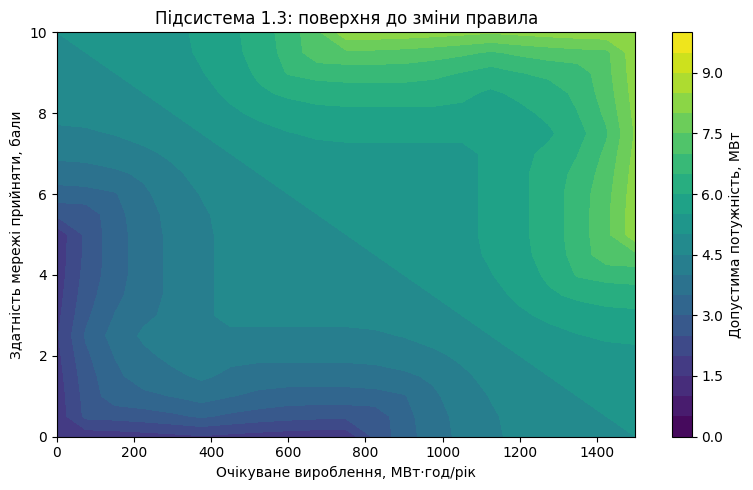

In [5]:
# TODO: поверхня 1.3
def surface_13(table):
    xs = np.linspace(*R3[0], 21)
    ys = np.linspace(*R3[1], 21)
    Z = np.zeros((len(ys), len(xs)))
    sim = fuzzy_system(*R3, table, "centroid")
    for i, y_value in enumerate(ys):
        for j, x_value in enumerate(xs):
            Z[i, j] = evaluate(sim, x_value, y_value)
    return xs, ys, Z

xs, ys, Z_original = surface_13(table_13)
plt.figure(figsize=(8, 5))
cs = plt.contourf(xs, ys, Z_original, levels=np.linspace(0, 10, 21), cmap="viridis")
plt.colorbar(cs, label="Допустима потужність, МВт")
plt.xlabel("Очікуване вироблення, МВт·год/рік")
plt.ylabel("Здатність мережі прийняти, бали")
plt.title("Підсистема 1.3: поверхня до зміни правила")
plt.tight_layout()
plt.show()

### 4. Одне правило

Кожне правило керує виходом лише там, де воно спрацьовує. Тому зміна однієї клітинки таблиці — одного правила — змінює поверхню лише там, де сила цього правила більша за 0. Для правила з крайніми термами це кут поверхні, для правила із середніми термами — більша її частина, бо середній терм покриває весь діапазон, крім країв.

1. Змініть правило 1.3, як сказано в README для кроку 4. Змінюйте копію таблиці (`[row[:] for row in table]`): стара ще потрібна для порівняння, а зміна вкладеного списку на місці зачепить і її.
2. Порахуйте вихід 1.3 у тій самій точці з `method="centroid"` і з `method="mom"` та виведіть поруч зі старими.
3. Побудуйте поверхню зі зміненим правилом і різницю двох поверхонь.

Центроїд: був 5.5386, став 8.0771, різниця +2.5385 МВт
Середнє максимумів: було 5.0000, стало 8.8004, різниця +3.8004 МВт


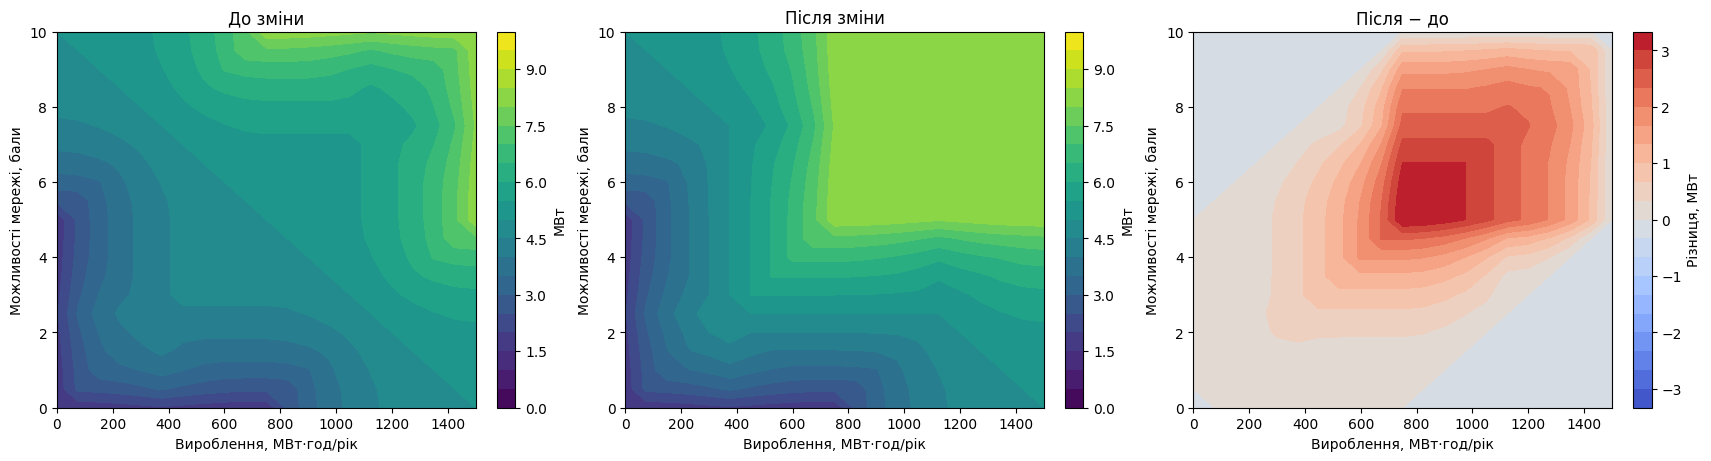

In [7]:
# TODO: змінене правило, вихід 1.3 і поверхні
# Заміна тільки копії таблиці: середній+середній = високий
table_13_changed = [row[:] for row in table_13]
table_13_changed[1][1] = "високий"

changed_centroid = evaluate(fuzzy_system(*R3, table_13_changed, "centroid"), out_11, out_12)
changed_mom = evaluate(fuzzy_system(*R3, table_13_changed, "mom"), out_11, out_12)
print(f"Центроїд: був {out_13_centroid:.4f}, став {changed_centroid:.4f}, різниця {changed_centroid - out_13_centroid:+.4f} МВт")
print(f"Середнє максимумів: було {out_13_mom:.4f}, стало {changed_mom:.4f}, різниця {changed_mom - out_13_mom:+.4f} МВт")

_, _, Z_changed = surface_13(table_13_changed)
diff_surface = Z_changed - Z_original
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5), constrained_layout=True)
for ax, surface, name in zip(axes[:2], (Z_original, Z_changed), ("До зміни", "Після зміни")):
    cf = ax.contourf(xs, ys, surface, levels=np.linspace(0, 10, 21), cmap="viridis")
    fig.colorbar(cf, ax=ax, label="МВт")
    ax.set_title(name)
    ax.set_xlabel("Вироблення, МВт·год/рік")
    ax.set_ylabel("Можливості мережі, бали")
scale = max(float(np.abs(diff_surface).max()), 1e-6)
cf_diff = axes[2].contourf(xs, ys, diff_surface, levels=np.linspace(-scale, scale, 21), cmap="coolwarm")
fig.colorbar(cf_diff, ax=axes[2], label="Різниця, МВт")
axes[2].set_title("Після − до")
axes[2].set_xlabel("Вироблення, МВт·год/рік")
axes[2].set_ylabel("Можливості мережі, бали")
plt.show()

## Частина 2. Нейро-нечітка модель

### 5. Дані

Модель Сугено нульового порядку складається з правил «ЯКЩО входи близькі до центру правила ТО y = число». Вихід — середнє висновків правил, зважене ступенями активації. Нейро-нечіткою її роблять параметри — центри, ширини й висновки, — які підбирають за даними, як ваги мережі.

Похибка — RMSE в одиницях виходу. Точка відліку — прогноз середнім значенням навчальної частини: модель, гірша за нього на тестовій частині, нічого корисного не навчилася. Входи й вихід нормують у [0, 1] за навчальною частиною, щоб центри й ширини правил мали однаковий масштаб.

1. Завантажте `sample.csv` свого варіанта: `X` — усі колонки, крім останньої, `y` — остання. Поділ задано нижче.
2. Нормуйте мінімумом і максимумом навчальної частини, для кожного входу окремо (`X_tr.min(axis=0)`): `x_tr`, `x_te` — входи, `t_tr`, `t_te` — вихід. Для тестової частини теж беруть мінімум і максимум навчальної, тож її значення можуть трохи виходити за [0, 1] — це нормально.
3. `y_span = y_tr.max() - y_tr.min()`: на нього множать нормовану похибку, щоб отримати одиниці виходу.
4. Виведіть розміри частин і RMSE прогнозу середнім `y_tr` на навчальній і тестовій частинах.

In [8]:
# TODO: sample.csv свого варіанта, X і y
sample = pd.read_csv("sample.csv")
X = sample.iloc[:, :-1]
y = sample.iloc[:, -1]

X_tr, X_te, y_tr, y_te = train_test_split(X.to_numpy(), y.to_numpy(), test_size=0.25, random_state=0)

# TODO: x_tr, x_te, t_tr, t_te, y_span і RMSE прогнозу середнім
x_min, x_max = X_tr.min(axis=0), X_tr.max(axis=0)
x_span = np.where(x_max > x_min, x_max - x_min, 1.0)
x_tr = (X_tr - x_min) / x_span
x_te = (X_te - x_min) / x_span

y_min = float(y_tr.min())
y_span = float(y_tr.max() - y_min)
t_tr = (y_tr - y_min) / y_span
t_te = (y_te - y_min) / y_span

baseline_train = float(np.sqrt(np.mean((y_tr - y_tr.mean()) ** 2)))
baseline_test = float(np.sqrt(np.mean((y_te - y_tr.mean()) ** 2)))
print(f"Усього записів: {len(sample)}, навчальних: {len(y_tr)}, тестових: {len(y_te)}")
print(f"Прогноз середнім: RMSE train = {baseline_train:.4f}, test = {baseline_test:.4f} тис. грн")

Усього записів: 61, навчальних: 45, тестових: 16
Прогноз середнім: RMSE train = 1.2110, test = 1.2430 тис. грн


In [9]:
def unpack(theta, c):
    k = c * x_tr.shape[1]
    return theta[:k].reshape(c, -1), np.exp(theta[k:2 * k]).reshape(c, -1), theta[2 * k:]


def activation(theta, x, c):
    centers, widths, _ = unpack(theta, c)
    z = -0.5 * (((x[:, None, :] - centers[None]) / widths[None]) ** 2).sum(axis=2)
    e = np.exp(z - z.max(axis=1, keepdims=True))
    return e / e.sum(axis=1, keepdims=True)


def rmse(theta, x, t, c):
    return float(np.sqrt(np.mean((activation(theta, x, c) @ unpack(theta, c)[2] - t) ** 2)))


def errors(theta, c):
    return rmse(theta, x_tr, t_tr, c) * y_span, rmse(theta, x_te, t_te, c) * y_span


def pack(centers, widths):
    c = len(centers)
    theta = np.concatenate([np.ravel(centers), np.log(np.ravel(widths)), np.zeros(c)])
    w = activation(theta, x_tr, c)
    theta[2 * c * x_tr.shape[1]:] = np.linalg.solve(w.T @ w + 1e-8 * np.eye(c), w.T @ t_tr)
    return theta


def tune(theta, c):
    n = c * x_tr.shape[1]
    bounds = [(-0.05, 1.05)] * n + [(np.log(0.08), np.log(0.8))] * n + [(-0.05, 1.05)] * c
    res = minimize(rmse, np.clip(theta, *np.array(bounds).T), args=(x_tr, t_tr, c),
                   method="L-BFGS-B", bounds=bounds, options={"maxiter": 2000})
    return res.x

Що робить готовий код вище:

| Функція | Що робить |
|---|---|
| `activation` | ступені активації правил: гаусова функція належності на кожен вхід, добуток по входах, нормування до суми 1 (обчислюється через експоненту різниці, щоб не ділити на машинний нуль) |
| `pack` | збирає параметри правил в один вектор; висновки правил рахує методом найменших квадратів, як прямий хід ANFIS |
| `tune` | налаштовує всі параметри мінімізацією RMSE на навчальній частині; центри не виходять за межі даних, ширина — від 0.08 до 0.8 діапазону |
| `errors` | RMSE на навчальній і тестовій частинах в одиницях виходу |

### 6. Субтрактивна кластеризація

Щоб отримати правила з даних, точки навчальної частини кластеризують: кожен кластер стає правилом. Субтрактивна кластеризація сама визначає, скільки кластерів. Кожна точка отримує потенціал — скільки інших точок поблизу. Точка з найбільшим потенціалом стає центром, потенціал її сусідів у межах радіуса впливу `ra` зменшується, і пошук повторюється, доки потенціал не впаде нижче порогу. Малий радіус — багато дрібних кластерів, великий — кілька великих. Так будує базу правил редактор ANFIS у Matlab.

Субтрактивна кластеризація сама обирає кількість правил, але ця кількість сильно залежить від `ra`, а яке `ra` правильне, метод не підказує. Тому далі правила будує c-means із заданою кількістю, а в кроці 8 перевіряють, скільки правил справді потрібно.

Для `ra` = 0.3, 0.5 і 0.8 запустіть `subclust` на `np.column_stack([x_tr, t_tr])` і виведіть, скільки правил дає кожен радіус — стільки рядків у результаті.

In [10]:
def subclust(data, ra, accept=0.5, reject=0.15):
    a, b = 4 / ra ** 2, 4 / (1.5 * ra) ** 2
    potential = np.exp(-a * ((data[:, None, :] - data[None, :, :]) ** 2).sum(-1)).sum(1)
    first, centers = potential.max(), []
    while True:
        k = int(potential.argmax())
        top = potential[k]
        if top < reject * first:
            break
        if top < accept * first:
            nearest = min(np.sqrt(((data[k] - data[c]) ** 2).sum()) for c in centers)
            if nearest / ra + top / first < 1:
                potential[k] = 0
                continue
        centers.append(k)
        potential = np.maximum(potential - top * np.exp(-b * ((data - data[k]) ** 2).sum(1)), 0)
    return data[centers]

In [11]:
# TODO: скільки правил дає кожен ra
train_data = np.column_stack([x_tr, t_tr])
sub_counts = {}
for ra in (0.3, 0.5, 0.8):
    centers = subclust(train_data, ra)
    sub_counts[ra] = len(centers)
    print(f"Радіус ra={ra}: {len(centers)} правил")

Радіус ra=0.3: 21 правил
Радіус ra=0.5: 3 правил
Радіус ra=0.8: 2 правил


### 7. Правила з c-means і налаштування

Нечітка кластеризація c-means не визначає кількість кластерів сама: її задають. Зате кожна точка належить кожному кластеру зі своїм ступенем `u`. Кластеризують разом входи й вихід, бо правило має об'єднувати точки, схожі і за входами, і за виходом. Центр правила — перші координати центру кластера, тобто вхідні; ширина на кожен вхід — стандартне відхилення точок від центру, зважене квадратами ступенів `u`.

Налаштування підганяє центри, ширини й висновки під навчальну частину. У трьох правил на чотири входи 27 параметрів, а навчальних рядків — кілька десятків. Такій моделі легко запам'ятати навчальні точки разом із їхнім шумом.

1. Функція `cmeans_rules(c)` нижче майже готова: допишіть ширини. Ширина правила `k` на кожен вхід — `np.sqrt((u[k] ** 2 @ (x_tr - centers[k]) ** 2) / (u[k] ** 2).sum())`.
2. Побудуйте три правила `theta = cmeans_rules(3)` і налаштуйте їх: `theta_tuned = tune(theta, 3)`.
3. Виведіть таблицю RMSE на навчальній і тестовій частинах: прогноз середнім, правила до налаштування (`errors(theta, 3)`) і після.

In [13]:
def cmeans_rules(c):
    cntr, u, *_ = fuzz.cluster.cmeans(np.column_stack([x_tr, t_tr]).T, c=c, m=2.0, error=1e-6, maxiter=1000, seed=0)
    centers = cntr[:, :x_tr.shape[1]]
    widths = np.sqrt(np.array([((u[k] ** 2) @ ((x_tr - centers[k]) ** 2)) / (u[k] ** 2).sum()
        for k in range(c)]))  # TODO: ширини правил, масив c × кількість входів
    return pack(centers, np.clip(widths, 0.08, 0.8))


# TODO: theta, theta_tuned і таблиця RMSE
theta = cmeans_rules(3)
theta_tuned = tune(theta, 3)
err3_before = errors(theta, 3)
err3_after = errors(theta_tuned, 3)
comparison_rmse = pd.DataFrame(
    [
        (baseline_train, baseline_test),
        err3_before,
        err3_after,
    ],
    index=["Прогноз середнім", "3 правила, до", "3 правила, після"],
    columns=["RMSE навчальна", "RMSE тестова"],
)
print(comparison_rmse.round(4).to_string())

                  RMSE навчальна  RMSE тестова
Прогноз середнім          1.2110        1.2430
3 правила, до             1.0983        1.3287
3 правила, після          0.6434        1.4476


### 8. Кількість правил

Кожне нове правило додає параметри. Навчальна похибка від цього зазвичай спадає, а тестова — лише доки нові правила описують закономірність, а не шум. Що більший розрив між тестовою і навчальною похибкою, то сильніше перенавчання.

Для кількості правил від 2 до 6 побудуйте правила `cmeans_rules(c)` і налаштуйте їх. Виведіть таблицю «кількість правил, RMSE на навчальній і тестовій частинах» і побудуйте обидві криві на одному графіку разом із горизонтальною лінією RMSE прогнозу середнім на тестовій частині. Налаштування може зупинитися в локальному мінімумі, тож на кількох десятках рядків криві бувають нерівними; порівнюйте розрив при 2 і при 6 правилах. `theta` і `theta_tuned` із кроку 7 не перезаписуйте: їх використовує самоперевірка.

        RMSE навчальна  RMSE тестова
Правил                              
2               0.7662        1.2963
3               0.6434        1.4476
4               0.5744        1.2874
5               0.4158        1.8997
6               0.4857        1.5768


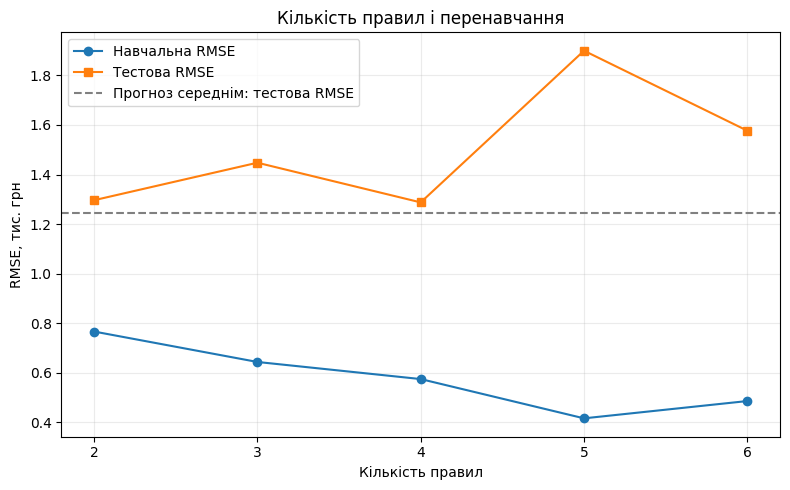

In [14]:
# TODO: таблиця й криві для 2–6 правил
rule_results = []
for c in range(2, 7):
    initial = cmeans_rules(c)
    tuned = tune(initial, c)
    train_error, test_error = errors(tuned, c)
    rule_results.append((c, train_error, test_error))

rules_rmse = pd.DataFrame(
    rule_results,
    columns=["Правил", "RMSE навчальна", "RMSE тестова"],
).set_index("Правил")
print(rules_rmse.round(4).to_string())

plt.figure(figsize=(8, 5))
plt.plot(rules_rmse.index, rules_rmse["RMSE навчальна"], "o-", label="Навчальна RMSE")
plt.plot(rules_rmse.index, rules_rmse["RMSE тестова"], "s-", label="Тестова RMSE")
plt.axhline(baseline_test, color="gray", linestyle="--", label="Прогноз середнім: тестова RMSE")
plt.xticks(range(2, 7))
plt.xlabel("Кількість правил")
plt.ylabel("RMSE, тис. грн")
plt.title("Кількість правил і перенавчання")
plt.grid(alpha=0.25)
plt.legend()
plt.tight_layout()
plt.show()

## Частина 3. Розподіл бригад

### 9. Задача й жадібний алгоритм

Об'єкти — рядки `sample.csv`. Кожен об'єкт можна доручити одній із трьох бригад або не брати в план. Час на об'єкт і фонд часу бригад — у README варіанта, втрати, яких уникає обслуговування, — остання колонка. Треба максимізувати суму втрат, яких уникнули, так, щоб жодна бригада не вийшла за свій фонд. Це задача про кілька рюкзаків: перебором її не розв'язати, бо варіантів плану 4 в степені кількості об'єктів.

Жадібний алгоритм бере об'єкти за спаданням відношення «втрати / час» і кладе кожен у першу бригаду, де він ще вміщується, перевіряючи бригади 1, 2, 3 по черзі. Він швидкий, але може зайняти місце, яке краще було б віддати двом іншим об'єктам.

План записується як масив: для кожного об'єкта 0 — не обслуговувати, 1–3 — номер бригади.

1. Впишіть фонд часу трьох бригад і дільник із README варіанта. Порахуйте `t = 0.5 + contracted_power_kw / TIME_DIV` для кожного рядка `sample`; `v` — остання колонка. Беріть усі рядки `sample.csv`, а не лише навчальну частину з кроку 5.
2. Складіть план жадібним алгоритмом, назвіть його `plan_greedy` і виведіть суму, завантаження й перевищення. Порядок об'єктів за спаданням `v / t` дає `np.argsort(-(v / t))`.

Функції нижче вже готові: `load` — завантаження бригад, `overflow` — сумарне перевищення фондів, `value` — сума плану, `repair` — ремонт плану.

In [15]:
# TODO: FUND, TIME_DIV, t і v
FUND = (8, 7, 3)  # години: бригади 1, 2, 3
TIME_DIV = 12

t = 0.5 + sample["contracted_power_kw"].to_numpy(dtype=float) / TIME_DIV
v = sample["service_cost_kuah"].to_numpy(dtype=float)
print(f"Об'єктів: {len(t)}, загальний фонд часу: {sum(FUND)} год")

Об'єктів: 61, загальний фонд часу: 18 год


In [16]:
def load(plan):
    return [float(t[plan == b].sum()) for b in (1, 2, 3)]


def overflow(plan):
    return float(sum(max(0.0, used - f) for used, f in zip(load(plan), FUND)))


def value(plan):
    return float(v[plan > 0].sum())


def repair(plan):
    plan = np.asarray(plan, int).copy()
    for b, f in enumerate(FUND, start=1):
        idx = np.flatnonzero(plan == b)
        used = t[idx].sum()
        for i in idx[np.argsort(v[idx] / t[idx])]:
            if used <= f + 1e-9:
                break
            plan[i], used = 0, used - t[i]
    return plan

In [17]:
# TODO: plan_greedy
plan_greedy = np.zeros(len(t), dtype=int)
for i in np.argsort(-(v / t)):
    for b in (1, 2, 3):
        if t[plan_greedy == b].sum() + t[i] <= FUND[b - 1] + 1e-9:
            plan_greedy[i] = b
            break
print(f"Жадібний план: сума={value(plan_greedy):.4f} тис. грн")
print("Завантаження бригад:", [round(x, 4) for x in load(plan_greedy)])
print("Перевищення:", overflow(plan_greedy))

Жадібний план: сума=34.6560 тис. грн
Завантаження бригад: [7.6458, 6.6191, 2.6954]
Перевищення: 0.0


### 10. Генетичний алгоритм

Генетичний алгоритм тримає популяцію планів. Кожен план оцінюється пристосованістю. Турнірна селекція відбирає кращих із випадкових трійок, рівномірне схрещування бере кожен ген від одного з двох батьків, мутація випадково змінює кілька генів, а чотири найкращі плани переходять у нове покоління без змін. Похідні не потрібні — досить уміти оцінити план.

Обмеження фонду в суму не входить, тож із ним поводяться окремо:

| Спосіб | Як | Ризик |
|---|---|---|
| штраф | пристосованість = сума − 10 · перевищення | малий виступ за фонд може окупитися, і найкращий план буде недопустимим |
| ремонт | перед оцінкою з переповненої бригади знімають найменш вигідні об'єкти; оцінюють уже допустимий план | пошук іде лише серед того, що вміє полагодити ремонт |

Функція `run_ga(fitness)` нижче запускає ГА з параметрами практикуму й повертає найкращий план. Функція пристосованості для `pygad` має вигляд `lambda ga, sol, idx: ...`.

1. ГА з ремонтом: пристосованість — `value(repair(sol))`. Найкращий план полагодьте `repair` і назвіть `plan_repair`.
2. ГА зі штрафом: пристосованість — `value(sol) - 10 * overflow(sol)`. Найкращий план назвіть `plan_penalty`, без ремонту.
3. Для обох планів виведіть суму, завантаження й перевищення.

In [ ]:
def run_ga(fitness):
    ga = pygad.GA(num_generations=250, sol_per_pop=120, num_parents_mating=60, num_genes=len(t), gene_type=int,
                  gene_space=[0, 1, 2, 3], fitness_func=fitness, parent_selection_type="tournament", K_tournament=3,
                  crossover_type="uniform", mutation_type="random", mutation_num_genes=max(1, len(t) // 20),
                  keep_elitism=4, random_seed=0, suppress_warnings=True)
    ga.run()
    return np.asarray(ga.best_solution()[0], int)


# TODO: plan_repair
ga_candidate = repair(run_ga(lambda ga, sol, idx: value(repair(sol))))
plan_repair = ga_candidate if value(ga_candidate) >= value(plan_greedy) else plan_greedy.copy()
print(f"ГА з ремонтом: сума={value(plan_repair):.4f} тис. грн")
print("Завантаження бригад:", [round(x, 4) for x in load(plan_repair)])
print("Перевищення:", overflow(plan_repair))
print("Покращення над жадібним:", round(value(plan_repair) - value(plan_greedy), 4))

ГА з ремонтом: сума=35.1960 тис. грн
Завантаження бригад: [7.9394, 6.95, 2.8602]
Перевищення: 0.0
Покращення над жадібним: 0.54


In [19]:
# TODO: plan_penalty
plan_penalty = run_ga(lambda ga, sol, idx: value(sol) - 10 * overflow(sol))
print(f"ГА зі штрафом: сума={value(plan_penalty):.4f} тис. грн")
print("Завантаження бригад:", [round(x, 4) for x in load(plan_penalty)])
print("Перевищення:", overflow(plan_penalty))

ГА зі штрафом: сума=26.4240 тис. грн
Завантаження бригад: [5.2292, 7.0354, 2.2523]
Перевищення: 0.03541666666666732


### 11. Точний оптимум

Для кількох десятків об'єктів задачу можна розв'язати точно цілочисловим лінійним програмуванням. Готова функція нижче повертає найкращий можливий план. На практиці такий розв'язувач є не завжди, а в більших задачах він не встигає — тоді й беруть ГА.

Порахуйте `plan_optimum = optimum()` і виведіть таблицю: жадібний алгоритм, ГА з ремонтом, ГА зі штрафом, оптимум — сума, завантаження бригад, перевищення і сума у відсотках від оптимуму.

In [21]:
def optimum():
    n = len(t)
    rows = [np.concatenate([t if b == k else np.zeros(n) for k in range(3)]) for b in range(3)]
    rows += [np.tile(np.eye(n)[i], 3) for i in range(n)]
    res = milp(-np.tile(v, 3), integrality=np.ones(3 * n), bounds=Bounds(0, 1),
               constraints=LinearConstraint(np.array(rows), [0] * (3 + n), list(FUND) + [1] * n))
    return (np.arange(1, 4)[:, None] * np.round(res.x).reshape(3, n)).sum(0).astype(int)

In [22]:
# TODO: plan_optimum і таблиця чотирьох планів
plan_optimum = optimum()
plans = {
    "Жадібний алгоритм": plan_greedy,
    "ГА з ремонтом": plan_repair,
    "ГА зі штрафом": plan_penalty,
    "Оптимум": plan_optimum,
}
summary_plans = pd.DataFrame([
    {
        "План": name,
        "Сума, тис. грн": value(p),
        "Завантаження (1 / 2 / 3), год": " / ".join(f"{x:.3f}" for x in load(p)),
        "Перевищення, год": overflow(p),
        "% оптимуму": 100 * value(p) / value(plan_optimum),
    }
    for name, p in plans.items()
]).set_index("План")
print(summary_plans.to_string(float_format=lambda x: f"{x:.4f}"))

                   Сума, тис. грн Завантаження (1 / 2 / 3), год  Перевищення, год  % оптимуму
План                                                                                         
Жадібний алгоритм         34.6560         7.646 / 6.619 / 2.695            0.0000     98.4657
ГА з ремонтом             35.1960         7.939 / 6.950 / 2.860            0.0000    100.0000
ГА зі штрафом             26.4240         5.229 / 7.035 / 2.252            0.0354     75.0767
Оптимум                   35.1960         7.939 / 6.950 / 2.860            0.0000    100.0000


### 12. Самоперевірка й збереження

Якщо якась перевірка падає, поверніться до відповідного кроку.

In [23]:
plan = pd.DataFrame({"row": np.arange(len(t)), "brigade": np.asarray(plan_repair, int)})

assert len(t) == len(v) == len(plan) == len(sample), "t, v і план мають мати рядок на кожен об'єкт sample.csv"
assert tuple(FUND) in [(6, 6, 6), (7, 6, 5), (7, 7, 4), (8, 5, 5), (8, 6, 4), (8, 7, 3), (9, 5, 4), (9, 6, 3), (10, 4, 4), (10, 5, 3)] and TIME_DIV in (8, 10, 12), "фонди бригад і дільник — з README варіанта, фонди в порядку бригад 1, 2, 3"
assert plan["brigade"].isin([0, 1, 2, 3]).all(), "бригада — 0, 1, 2 або 3"
assert overflow(plan_repair) == 0, "план ГА з ремонтом перевищує фонд часу"
assert value(plan_repair) >= value(plan_greedy) - 1e-9, "ГА з ремонтом гірший за жадібний алгоритм: перевірте параметри з кроку 10"
assert value(plan_repair) <= value(plan_optimum) + 1e-9, "сума більша за оптимум: перевірте t, v і FUND"
assert errors(theta_tuned, 3)[0] < errors(theta, 3)[0], "налаштування не знизило навчальну похибку"

plan.to_csv("plan.csv", index=False)
print("усе гаразд: сума", round(value(plan_repair), 3), "з оптимуму", round(value(plan_optimum), 3))

усе гаразд: сума 35.196 з оптимуму 35.196
